In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, GlobalAveragePooling2D, Dense, Dropout, BatchNormalization, MaxPooling2D, Reshape, Multiply
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.applications import VGG16, VGG19, DenseNet121, ResNet50, MobileNet, InceptionV3, Xception
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import seaborn as sns

2026-11-05 14:33:34.677598: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793889214.883323      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793889214.944899      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793889215.428726      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793889215.428762      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793889215.428765      23 computation_placer.cc:177] computation placer alr

In [2]:
# Parameters
input_shape = (224, 224, 3)
num_classes = 5
lr = 1e-5
bs = 32
ep = 30

# Define paths
base_dir = "/kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed"
cropped_dirs = {
    cls: os.path.join(base_dir, cls, cls, "CROPPED")
    for cls in ["im_Dyskeratotic", "im_Metaplastic", "im_Koilocytotic", "im_Parabasal", "im_Superficial-Intermediate"]
}
uncropped_dirs = {
    cls: os.path.join(base_dir, cls, cls)
    for cls in ["im_Dyskeratotic", "im_Metaplastic", "im_Koilocytotic", "im_Parabasal", "im_Superficial-Intermediate"]
}

In [3]:
import re

def load_images_from_directory(directory, target_size=(224, 224)):
    images, filenames = [], []
    for filename in sorted(os.listdir(directory)):
        img = cv2.imread(os.path.join(directory, filename))
        if img is not None:
            img = cv2.resize(img, target_size)
            images.append(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            filenames.append(filename)
    return np.array(images), filenames

cropped_images, cropped_labels, cropped_groups = {}, {}, {}
for cls, dir_path in cropped_dirs.items():
    images, filenames = load_images_from_directory(dir_path)
    cropped_images[cls] = images
    cropped_labels[cls] = np.full(len(images), cls)
    cropped_groups[cls] = np.array([f"{cls}_{re.split(r'[_.]', fn)[0]}" for fn in filenames])

X_cropped = np.concatenate(list(cropped_images.values()))
y_cropped = np.concatenate(list(cropped_labels.values()))
groups    = np.concatenate(list(cropped_groups.values()))

label_to_index = {cls: idx for idx, cls in enumerate(cropped_dirs.keys())}
y_cropped = np.array([label_to_index[label] for label in y_cropped])
y_cropped = to_categorical(y_cropped, num_classes=5)

def group_split_per_class(y_int, groups, fractions=(0.80, 0.15, 0.05)):
    rng = np.random.RandomState(42)
    split_of_group = {}
    for c in np.unique(y_int):
        idx = np.where(y_int == c)[0]
        ugroups = np.unique(groups[idx])
        rng.shuffle(ugroups)
        sizes = {g: np.sum(groups[idx] == g) for g in ugroups}
        targets = [f * len(idx) for f in fractions]
        filled = [0, 0, 0]
        for g in ugroups:
            s = int(np.argmax([(targets[k] - filled[k]) / targets[k] for k in range(3)]))
            split_of_group[g] = s
            filled[s] += sizes[g]
    return np.array([split_of_group[g] for g in groups])

split_id = group_split_per_class(y_cropped.argmax(axis=1), groups)

X_train, y_train = X_cropped[split_id == 0], y_cropped[split_id == 0]
X_val,   y_val   = X_cropped[split_id == 1], y_cropped[split_id == 1]
X_test,  y_test  = X_cropped[split_id == 2], y_cropped[split_id == 2]

g_train, g_val, g_test = (set(groups[split_id == k]) for k in range(3))
assert not (g_train & g_val) and not (g_train & g_test) and not (g_val & g_test), "DATA LEAK!"
print(f"Train: {len(X_train)} imgs / {len(g_train)} groups")
print(f"Val  : {len(X_val)} imgs / {len(g_val)} groups")
print(f"Test : {len(X_test)} imgs / {len(g_test)} groups")

Train: 3192 imgs / 758 groups
Val  : 630 imgs / 148 groups
Test : 227 imgs / 60 groups


In [4]:
# Data augmentation
datagen = ImageDataGenerator(
    rotation_range=20,         # Random rotation up to 20 degrees
    zoom_range=[0.8, 1.0],     # Zoom out by up to 20%
    brightness_range=[0.9, 1.1],  
    horizontal_flip=True,
    vertical_flip=True,
    preprocessing_function=lambda x: tf.image.adjust_contrast(x, np.random.uniform(0.9, 1.1)),  # Custom contrast adjustment
    fill_mode='nearest'
)

# Fit the generator to the training data
datagen.fit(X_train)

In [5]:
base_model = Xception(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Add the minimal classification head
x = base_model.output
x = GlobalAveragePooling2D()(x)                  # Reduces feature maps to a vector
output_layer = Dense(5, activation='softmax')(x)  # 5 classes

# Create the full model
model = Model(inputs=base_model.input, outputs=output_layer)
model.compile(optimizer=Adam(learning_rate=lr), loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

I0000 00:00:1793890062.306687      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793890062.313044      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 111, 111,  │        864 │ input_layer[0][0] │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_bn     │ (None, 111, 111,  │        128 │ block1_conv1[0][… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_act    │ (None, 111, 111,  │          0 │ block1_conv1_bn[… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 109, 109,  │     18,432 │ block1_conv1_act… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_bn     │ (None, 109, 109,  │        256 │ block1_conv2[0][… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_act    │ (None, 109, 109,  │          0 │ block1_conv2_bn[… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1     │ (None, 109, 109,  │      8,768 │ block1_conv2_act… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1_bn  │ (None, 109, 109,  │        512 │ block2_sepconv1[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_act │ (None, 109, 109,  │          0 │ block2_sepconv1_… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2     │ (None, 109, 109,  │     17,536 │ block2_sepconv2_… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_bn  │ (None, 109, 109,  │        512 │ block2_sepconv2[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 55, 55,    │      8,192 │ block1_conv2_act… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 55, 55,    │          0 │ block2_sepconv2_… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 55, 55,    │        512 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 55, 55,    │          0 │ block2_pool[0][0… │
│                     │ 128)              │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_sepconv1_act │ (None, 55, 55,    │          0 │ add[0][0]       

 Total params: 20,871,725 (79.62 MB)

 Trainable params: 20,817,197 (79.41 MB)

 Non-trainable params: 54,528 (213.00 KB)

In [6]:
class_counts = np.sum(y_train, axis=0)           
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(num_classes),
    y=np.argmax(y_train, axis=1)
)

class_weight_dict = dict(enumerate(class_weights))

print("Class counts (train):", class_counts.astype(int))
print("Class weights:", class_weight_dict)

Class counts (train): [637 627 643 624 661]
Class weights: {0: np.float64(1.0021978021978022), 1: np.float64(1.018181818181818), 2: np.float64(0.9928460342146189), 3: np.float64(1.023076923076923), 4: np.float64(0.9658093797276853)}


In [7]:
history = model.fit(
    datagen.flow(X_train, y_train, batch_size=bs),
    validation_data=(X_val, y_val),
    epochs=ep,
    batch_size=bs,
    class_weight=class_weight_dict
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30


I0000 00:00:1793890091.048777      66 service.cc:152] XLA service 0x7a1a10001f20 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793890091.048827      66 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1793890091.048834      66 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1793890095.013686      66 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-11-05 14:48:25.025569: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 14:48:25.207344: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 14:48:26.762169: E external/local_xl

 51/100 ━━━━━━━━━━━━━━━━━━━━ 38s 777ms/step - accuracy: 0.2632 - loss: 1.5924

2026-11-05 14:49:41.753109: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 14:49:41.921542: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 14:49:43.291160: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 14:49:43.432734: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 14:49:44.456589: E external/local_xla/xla/stream_

100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3590 - loss: 1.5176

2026-11-05 14:50:58.604004: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 14:50:58.771949: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 14:51:00.291496: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 14:51:00.427048: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 14:51:01.400407: E external/local_xla/xla/stream_

100/100 ━━━━━━━━━━━━━━━━━━━━ 196s 1s/step - accuracy: 0.3606 - loss: 1.5161 - val_accuracy: 0.5524 - val_loss: 1.2367
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 89s 885ms/step - accuracy: 0.7915 - loss: 0.9402 - val_accuracy: 0.8000 - val_loss: 0.6526
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 88s 881ms/step - accuracy: 0.8887 - loss: 0.5488 - val_accuracy: 0.8921 - val_loss: 0.3720
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 88s 883ms/step - accuracy: 0.9066 - loss: 0.3783 - val_accuracy: 0.9238 - val_loss: 0.2663
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 88s 884ms/step - accuracy: 0.9160 - loss: 0.2983 - val_accuracy: 0.9349 - val_loss: 0.2210
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 89s 888ms/step - accuracy: 0.9276 - loss: 0.2356 - val_accuracy: 0.9429 - val_loss: 0.2012
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 89s 889ms/step - accuracy: 0.9385 - loss: 0.2062 - val_accuracy: 0.9429 - val_loss: 0.1889
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 89s 885ms/step - accuracy: 0.9399 - loss: 0.1972 - val_a

7/8 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.8958 - loss: 0.2974

2026-11-05 15:33:54.598910: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 15:33:54.734387: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 15:33:55.431758: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 15:33:55.564347: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 15:33:56.273002: E external/local_xla/xla/stream_

8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.9003 - loss: 0.2802
Test Loss: 0.220284
Test Accuracy: 0.916300


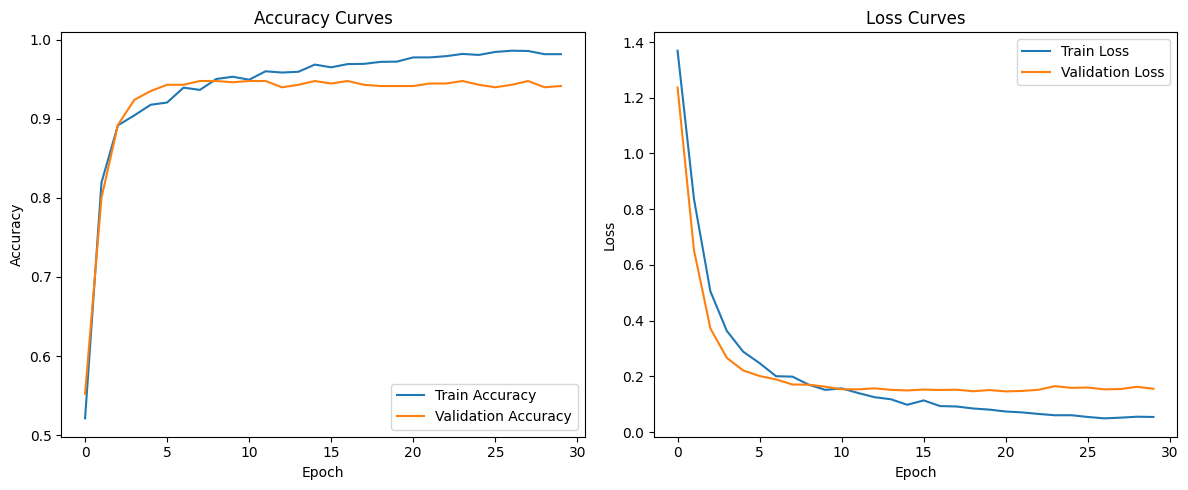

8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 664ms/step
Classification Report (Test Set):
                             precision    recall  f1-score   support

            im_Dyskeratotic   1.000000  0.911111  0.953488        45
             im_Metaplastic   0.941176  0.780488  0.853333        41
            im_Koilocytotic   0.828125  0.898305  0.861789        59
               im_Parabasal   0.928571  1.000000  0.962963        39
im_Superficial-Intermediate   0.934783  1.000000  0.966292        43

                   accuracy                       0.916300       227
                  macro avg   0.926531  0.917981  0.919573       227
               weighted avg   0.920077  0.916300  0.915618       227



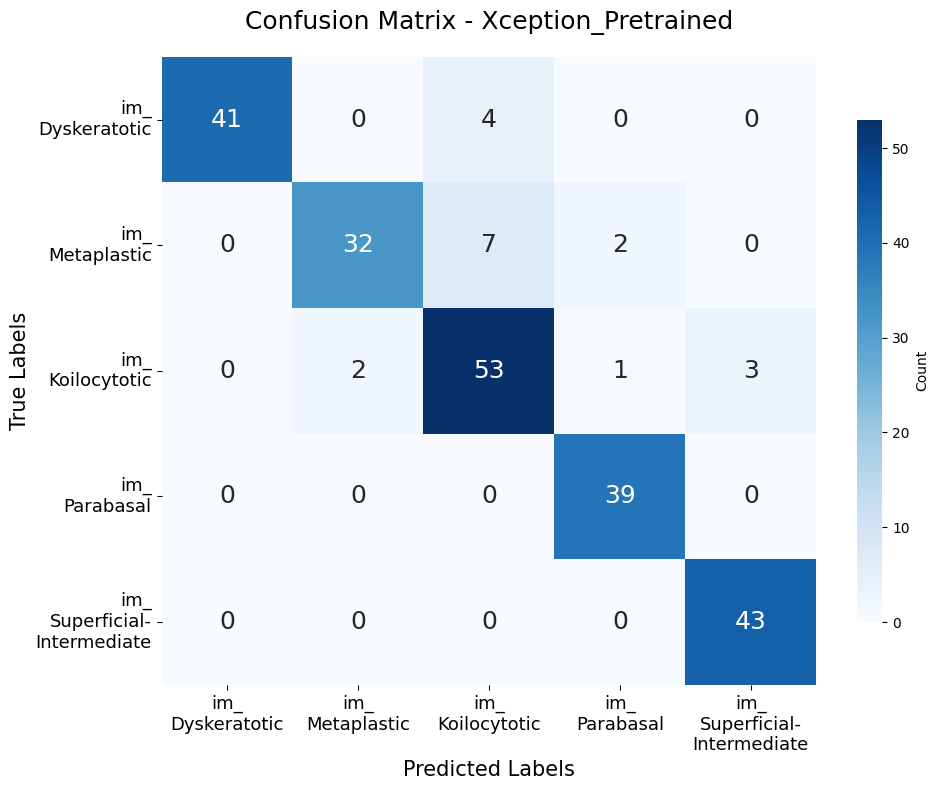

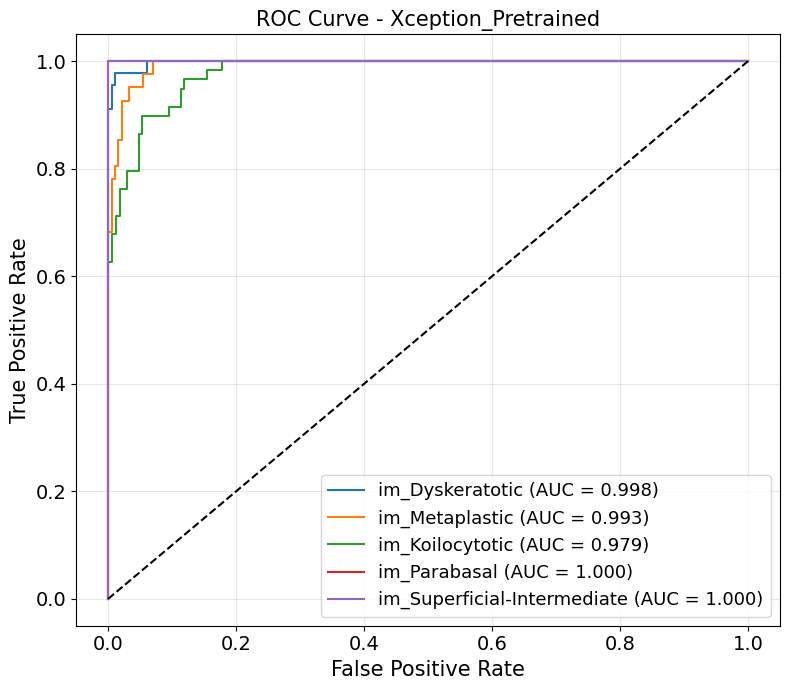

Model saved successfully.


In [8]:
# ===============================
# Final Test Evaluation
# ===============================
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print(f"Test Loss: {test_loss:.6f}")
print(f"Test Accuracy: {test_accuracy:.6f}")


# ===============================
# Training Curves (Train + Val)
# ===============================
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curves')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


# ===============================
# Predictions on TEST set only
# ===============================
y_pred_test = model.predict(X_test, verbose=1)

y_pred_classes = np.argmax(y_pred_test, axis=1)
y_true_classes = np.argmax(y_test, axis=1)


# ===============================
# Classification Report (TEST)
# ===============================
print("Classification Report (Test Set):")
print(
    classification_report(
        y_true_classes,
        y_pred_classes,
        target_names=list(cropped_dirs.keys()),
        digits=6        
    )
)


# ===============================
# Confusion Matrix (TEST)
# ===============================
class_names = list(label_to_index.keys())
class_names_wrapped = [
    name.replace('_', '_\n').replace('-', '-\n')
    for name in class_names
]
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(10, 8))           

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names_wrapped,
    yticklabels=class_names_wrapped,
    annot_kws={"size": 18},           
    cbar_kws={"label": "Count", "shrink": 0.8}
)

# Font size adjustments
plt.xticks(fontsize=13, rotation=0, ha='center')   
plt.yticks(fontsize=13, rotation=0)

plt.xlabel("Predicted Labels", fontsize=15)
plt.ylabel("True Labels",      fontsize=15)
plt.title("Confusion Matrix - Xception_Pretrained", fontsize=18, pad=20)

plt.tight_layout()
plt.show()


# ===============================
# ROC Curve & AUC (TEST)
# ===============================
num_classes = y_test.shape[1]
fpr = {}
tpr = {}
roc_auc = {}

class_names = list(label_to_index.keys())          

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_pred_test[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8, 7))   

for i in range(num_classes):
    plt.plot(
        fpr[i],
        tpr[i],
        label=f'{class_names[i]} (AUC = {roc_auc[i]:.3f})'   
    )

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate',      fontsize=15)
plt.ylabel('True Positive Rate',      fontsize=15)
plt.title('ROC Curve - Xception_Pretrained',      fontsize=15)
plt.legend(loc='lower right', fontsize=13)
plt.grid(True, alpha=0.3)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.show()


# ===============================
# Save Model
# ===============================
model.save("cervical_cancer_model.h5")
print("Model saved successfully.")